In [10]:
import os
from pathlib import Path
import pandas as pd
import sys
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path("..").resolve()))

print("working directory:", os.getcwd())
DATA = Path("..") / "data"
print("data folder:", DATA.resolve(), "| exists:", DATA.exists())
print(sorted(p.name for p in DATA.glob("*")))

working directory: /Users/chizobawisdom/Portfolio/Utility_and_Automation/edge-ai-pdm/notebooks
data folder: /Users/chizobawisdom/Portfolio/Utility_and_Automation/edge-ai-pdm/data | exists: True
['PdM_errors.csv', 'PdM_failures.csv', 'PdM_machines.csv', 'PdM_maint.csv', 'PdM_telemetry.csv']


In [11]:
tel = pd.read_csv(DATA / "PdM_telemetry.csv", parse_dates=["datetime"])
fail = pd.read_csv(DATA / "PdM_failures.csv", parse_dates=["datetime"])
print(tel.shape, fail.shape)
print(tel["machineID"].nunique(), "machines")
print(fail["failure"].value_counts())

(876100, 6) (761, 3)
100 machines
failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64


In [ ]:
# data quality checks
print(tel["datetime"].min(), "->", tel["datetime"].max())
print(tel.isna().sum().sum(), "missing values")
print(tel.groupby("machineID").size().agg(["min", "max"]))
print(fail.groupby(["machineID", "datetime"]).size().value_counts())
print(fail["datetime"].dt.hour.value_counts().head())
print(tel.describe().round(1))

2015-01-01 06:00:00 -> 2016-01-01 06:00:00
0 missing values
min    8761
max    8761
dtype: int64
1    677
2     42
Name: count, dtype: int64
datetime
6    743
3     18
Name: count, dtype: int64
                         datetime  machineID      volt    rotate  pressure  \
count                      876100   876100.0  876100.0  876100.0  876100.0   
mean   2015-07-02 17:59:59.999999       50.5     170.8     446.6     100.9   
min           2015-01-01 06:00:00        1.0      97.3     138.4      51.2   
25%           2015-04-02 12:00:00       25.8     160.3     412.3      93.5   
50%           2015-07-02 18:00:00       50.5     170.6     447.6     100.4   
75%           2015-10-02 00:00:00       75.2     181.0     482.2     107.6   
max           2016-01-01 06:00:00      100.0     255.1     695.0     186.0   
std                           NaN       28.9      15.5      52.7      11.0   

       vibration  
count   876100.0  
mean        40.4  
min         14.9  
25%         36.8  
50%     

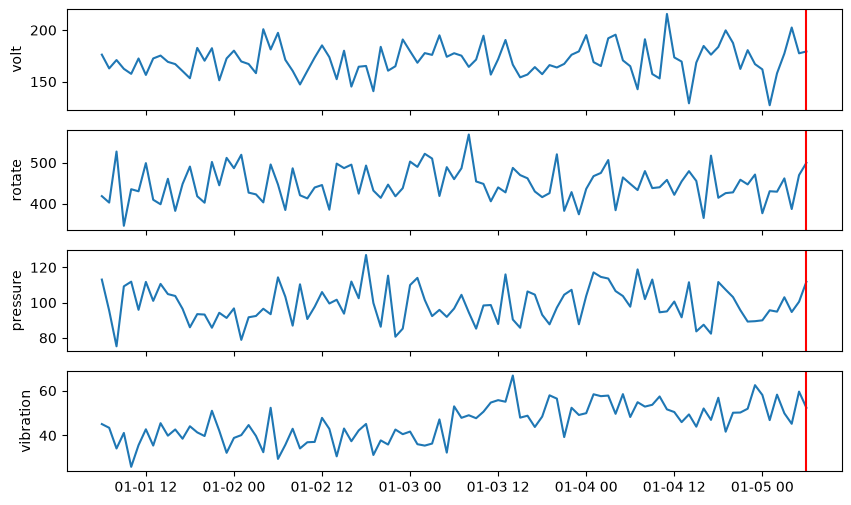

In [17]:
# test one machine before a failure
m = fail["machineID"].iloc[0]; t = fail.loc[fail["machineID"] == m, "datetime"].iloc[0]
d = tel[(tel["machineID"] == m) & tel["datetime"].between(t - pd.Timedelta(days=14), t)]
fig, ax = plt.subplots(4, 1, figsize=(10, 6), sharex=True)
for a, s in zip(ax, ["volt", "rotate", "pressure", "vibration"]):
    a.plot(d["datetime"], d[s]); a.axvline(t, color="r"); a.set_ylabel(s)
plt.show()

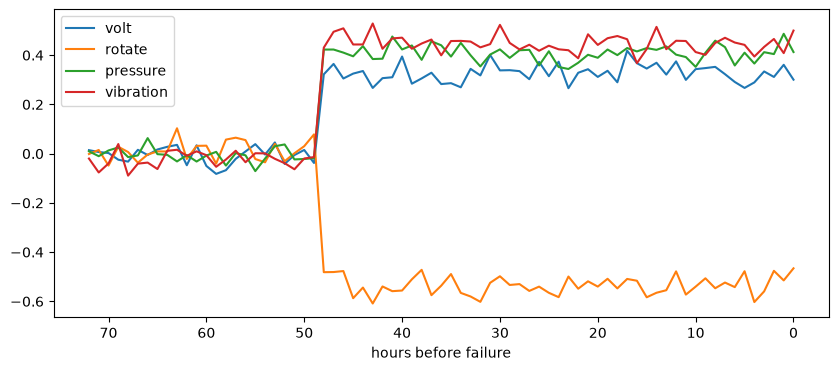

In [19]:
# average telemetry for all machines
sensors = ["volt", "rotate", "pressure", "vibration"]
z = tel.copy(); z[sensors] = (z[sensors] - z[sensors].mean()) / z[sensors].std()
z = z.set_index(["machineID", "datetime"]).sort_index()
rows = []
for m, t in fail[["machineID", "datetime"]].drop_duplicates().itertuples(index=False):
    w = z.loc[m].loc[t - pd.Timedelta(hours=72): t, sensors]
    rows.append(w.assign(h=((t - w.index) / pd.Timedelta(hours=1)).astype(int)).reset_index(drop=True))
prof = pd.concat(rows).groupby("h").mean()
ax = prof.plot(figsize=(10, 4)); ax.invert_xaxis(); ax.set_xlabel("hours before failure"); plt.show()

In [20]:
# summary of the last few hours before failure
df = tel.sort_values(["machineID", "datetime"]).reset_index(drop=True)
g = df.groupby("machineID")[sensors]
for w in [3, 12, 24]:
    for fn in ["mean", "std"]:
        r = getattr(g.rolling(w), fn)().reset_index(level = 0, drop=True)
        df = df.join(r, rsuffix=f"_{fn}_{w}")
print(df.shape)

/var/folders/0m/cxpqhx_12wgg_3yymy0r9n180000gn/T/ipykernel_43245/1857150252.py:7: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  df = df.join(r, rsuffix=f"_{fn}_{w}")


(876100, 30)


In [21]:
ft = fail[["machineID", "datetime"]].drop_duplicates().rename(columns={"datetime": "fail_time"})
ft["datetime"] = ft["fail_time"]
df = pd.merge_asof(df.sort_values("datetime"), ft.sort_values("datetime"),
                   on="datetime", by="machineID", direction="forward")
df["hours_to_fail"] = (df["fail_time"] - df["datetime"]).dt.total_seconds() / 3600
df["y"] = (df["hours_to_fail"] <= 48).astype(int)
print("positive rate:", df["y"].mean().round(4))

positive rate: 0.0396


In [22]:
feats = [c for c in df.columns if "_mean" in c or "_std" in c]
df = df.dropna(subset=feats)
cut = pd.Timestamp("2015-09-01")
train = df[df["datetime"] < cut - pd.Timedelta(hours=48)]
test = df[df["datetime"] >= cut]
for name, d in [("train", train), ("test", test)]:
    print(name, d.shape, "positives:", d["y"].sum(), f"({d['y'].mean():.3f})")

train (575500, 33) positives: 23069 (0.040)
test (293500, 33) positives: 10942 (0.037)


In [23]:
# what can a single feature do?
from sklearn.metrics import average_precision_score as ap
base = test["y"].mean()
res = {f: max(ap(test["y"], test[f]), ap(test["y"], -test[f])) for f in feats}
res = pd.Series(res).sort_values(ascending=False)
print(f"random baseline: {base:.3f}")
print(res.head(10).round(3))

random baseline: 0.037
rotate_mean_12       0.197
rotate_mean_24       0.179
rotate_mean_3        0.176
vibration_mean_12    0.119
vibration_mean_3     0.117
volt_mean_12         0.116
vibration_mean_24    0.110
volt_mean_24         0.107
volt_mean_3          0.096
pressure_mean_12     0.093
dtype: float64


In [24]:
# train a simple model
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
models = {"logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "hist_gb": HistGradientBoostingClassifier(random_state=42)}
for name, m in models.items():
    m.fit(train[feats], train["y"])
    print(name, round(ap(test["y"], m.predict_proba(test[feats])[:, 1]), 3))

logreg 0.326
hist_gb 0.319


In [27]:
base = train.groupby("machineID")[sensors].median()
print((base.std() / df[sensors].std()).round(2))

volt         0.02
rotate       0.02
pressure     0.02
vibration    0.02
dtype: float64


In [31]:
tr, te = train.copy(), test.copy()
for d in (tr, te):
    for s in sensors:
        for w in [3, 12, 24]:
            d[f"{s}_dev_{w}"] = d[f"{s}_mean_{w}"] - d["machineID"].map(base[s])
dev = [c for c in tr.columns if "_dev_" in c]
vcut = pd.Timestamp("2015-06-15")
tr_in, val = tr[tr["datetime"] < vcut - pd.Timedelta(hours=48)], tr[tr["datetime"] >= vcut]
for name, cols in [("global features", feats), ("global + per-machine deviation", feats + dev)]:
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr_in[cols], tr_in["y"])
    print(name, round(ap(val["y"], m.predict_proba(val[cols])[:, 1]), 3))

global features 0.327
global + per-machine deviation 0.345


In [33]:
# define when an alert fires
def alerts(d, thr, cool=48):
    out = []
    for m, g in d[d["p"] > thr].groupby("machineID"):
        last = None
        for t in g["datetime"]:
            if last is None or (t - last) >= pd.Timedelta(hours=cool):
                out.append((m, t)); last = t
    return pd.DataFrame(out, columns=["machineID", "datetime"])

# define which failure events are predicted by an alert
def evaluate(d, thr):
    a = alerts(d, thr).merge(d[["machineID", "datetime", "y", "fail_time"]], on=["machineID", "datetime"])
    events = d.loc[d["y"] == 1, ["machineID", "fail_time"]].drop_duplicates()
    hits = a.loc[a["y"] == 1, ["machineID", "fail_time"]].drop_duplicates()
    caught = events.merge(hits, how="left", indicator=True)["_merge"].eq("both").mean()
    weeks = (d["datetime"].max() - d["datetime"].min()).days / 7
    return caught, (a["y"] == 0).sum() / (d["machineID"].nunique() * weeks)

# choose threshold on validation period
m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr_in[feats], tr_in["y"])
val = val.assign(p=m.predict_proba(val[feats])[:, 1])
for thr in [0.2, 0.3, 0.5, 0.7, 0.9]:
    c, fa = evaluate(val, thr)
    print(f"thr={thr}: failures caught {c:.0%} | false alarms per machine-week {fa:.2f}")

thr=0.2: failures caught 91% | false alarms per machine-week 0.37
thr=0.3: failures caught 77% | false alarms per machine-week 0.25
thr=0.5: failures caught 36% | false alarms per machine-week 0.09
thr=0.7: failures caught 22% | false alarms per machine-week 0.03
thr=0.9: failures caught 12% | false alarms per machine-week 0.01


In [34]:
# Warning time and alert counts at threshold 0.3
cols = ["machineID", "datetime", "y", "fail_time", "hours_to_fail"]
a = alerts(val, 0.3).merge(val[cols], on=["machineID", "datetime"])
lead = a[a["y"] == 1].groupby(["machineID", "fail_time"])["hours_to_fail"].max()
print(lead.describe().round(1))
print("alerts inside a warning window:", (a["y"] == 1).sum(), "| false alerts:", (a["y"] == 0).sum())

count    119.0
mean      26.1
std       13.5
min        0.0
25%       14.0
50%       26.0
75%       37.5
max       48.0
Name: hours_to_fail, dtype: float64
alerts inside a warning window: 119 | false alerts: 265


In [35]:
final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[feats], train["y"])
test_p = test.assign(p=final.predict_proba(test[feats])[:, 1])
c, fa = evaluate(test_p, 0.3)
print(f"TEST thr=0.3: failures caught {c:.0%} | false alarms per machine-week {fa:.2f}")

TEST thr=0.3: failures caught 81% | false alarms per machine-week 0.27
